<a href="https://colab.research.google.com/github/pranalirakhunde32-ctrl/MDM_Tasks_EE513/blob/main/Traffic_Congestion_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: Libraries Import

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 5)
print("Libraries imported successfully.")

Libraries imported successfully.


Cell 2: Load Dataset

In [4]:
file_name = 'Traffic.csv'
df = pd.read_csv(file_name)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (2976, 9)

First 5 rows:


,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,31,0,4,4,39,low
1,12:15:00 AM,10,Tuesday,49,0,3,3,55,low
2,12:30:00 AM,10,Tuesday,46,0,3,6,55,low
3,12:45:00 AM,10,Tuesday,51,0,2,5,58,low
4,1:00:00 AM,10,Tuesday,57,6,15,16,94,normal


Cell 3: Feature Engineering & Preprocessing

In [5]:
# Time se Hour aur Minute nikalna
df['Time_dt'] = pd.to_datetime(df['Time'], format='%I:%M:%S %p')
df['Hour'] = df['Time_dt'].dt.hour
df['Minute'] = df['Time_dt'].dt.minute

# Day of week ko numeric me map karna
days_map = {
    'Monday': 0, 'Tuesday': 1, 'Wednesday': 2,
    'Thursday': 3, 'Friday': 4, 'Saturday': 5, 'Sunday': 6
}
df['DayOfWeek'] = df['Day of the week'].map(days_map)
df['IsWeekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

# Cyclical Encoding (Sine/Cosine)
df['Hour_Sin'] = np.sin(2 * np.pi * df['Hour'] / 24.0)
df['Hour_Cos'] = np.cos(2 * np.pi * df['Hour'] / 24.0)

df[['Time', 'Date', 'Day of the week', 'Hour', 'Total', 'Traffic Situation']].head()

,Time,Date,Day of the week,Hour,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,0,39,low
1,12:15:00 AM,10,Tuesday,0,55,low
2,12:30:00 AM,10,Tuesday,0,55,low
3,12:45:00 AM,10,Tuesday,0,58,low
4,1:00:00 AM,10,Tuesday,1,94,normal


Cell 4: Exploratory Data Analysis (Visualizations)

/tmp/ipykernel_1622/1835680951.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Traffic Situation', order=['low', 'normal', 'high', 'heavy'], palette='viridis', ax=axes[1])


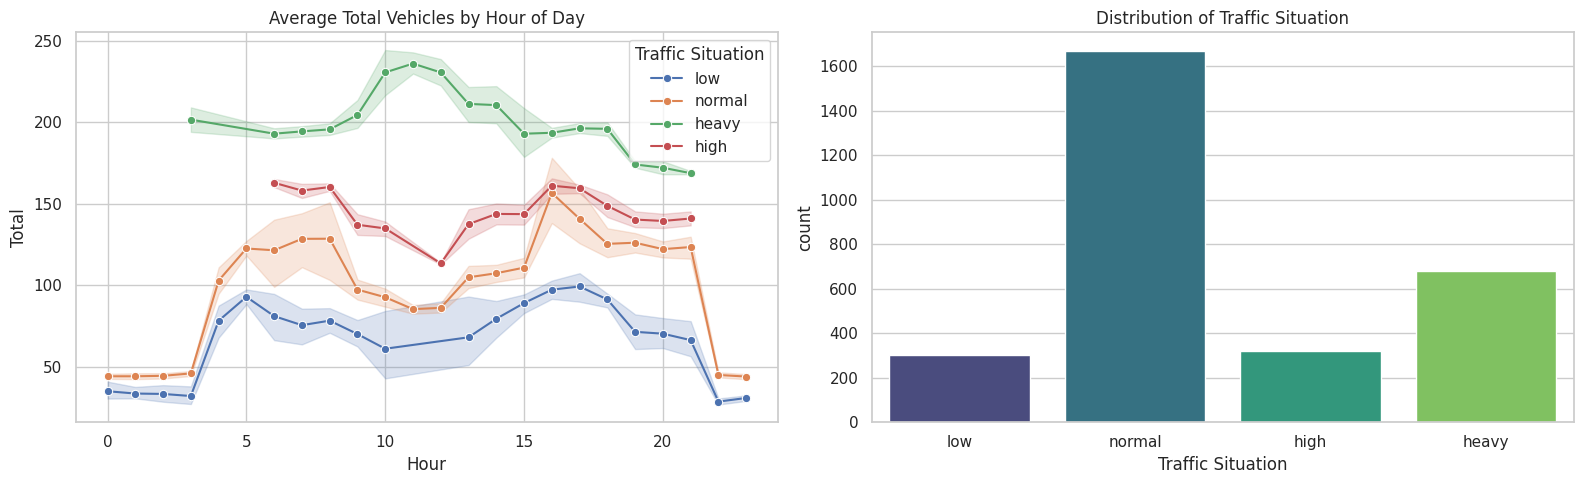

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Hour vs Total Traffic
sns.lineplot(data=df, x='Hour', y='Total', hue='Traffic Situation', marker='o', ax=axes[0])
axes[0].set_title("Average Total Vehicles by Hour of Day")

# Plot 2: Traffic Situation Distribution
sns.countplot(data=df, x='Traffic Situation', order=['low', 'normal', 'high', 'heavy'], palette='viridis', ax=axes[1])
axes[1].set_title("Distribution of Traffic Situation")

plt.tight_layout()
plt.show()

Cell 5: Train / Test Split

In [7]:
features = [
    'Date', 'Hour', 'Minute', 'DayOfWeek', 'IsWeekend',
    'Hour_Sin', 'Hour_Cos', 'CarCount', 'BikeCount', 'BusCount', 'TruckCount', 'Total'
]
target = 'Traffic Situation'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training Samples: {len(X_train)} | Testing Samples: {len(X_test)}")

Training Samples: 2380 | Testing Samples: 596


Cell 6: Model Training & Evaluation

Accuracy: 99.66%

--- Classification Report ---
              precision    recall  f1-score   support

       heavy       0.99      1.00      1.00       137
        high       1.00      0.98      0.99        64
         low       1.00      1.00      1.00        61
      normal       1.00      1.00      1.00       334

    accuracy                           1.00       596
   macro avg       1.00      1.00      1.00       596
weighted avg       1.00      1.00      1.00       596



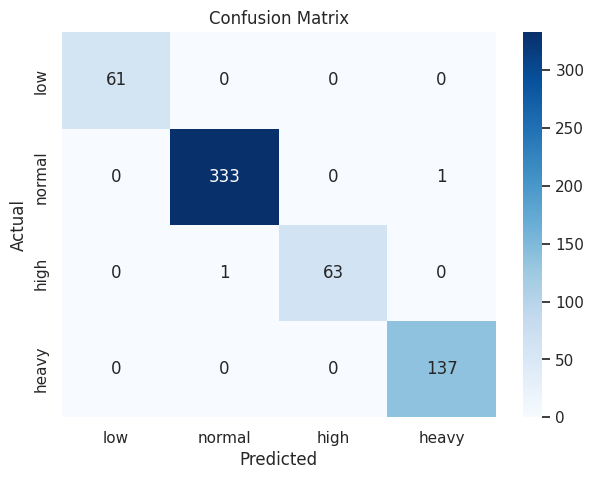

In [8]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=['low', 'normal', 'high', 'heavy'])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['low', 'normal', 'high', 'heavy'],
            yticklabels=['low', 'normal', 'high', 'heavy'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()